In [1]:
import numpy as np
import pandas as pd

In [2]:
data_topic = pd.read_csv('*********qa.csv')
data_topic.head()

,Time,question,answer,Unnamed: 3,Unnamed: 4,Unnamed: 5,
0,2022/12/30 11:12,尊敬的董秘，贵公司网站上看到新推出的阳康安心检标准款，目前销售了155815件，单价是529...,尊敬的投资者，您好！公司官网目前显示的相关数据包括已经下单并已经完成支付的订单数量，数据准确...,NaN,NaN,NaN,NaN
1,2022/12/29 21:21,近期出现肺部感染的人越来越多，医院里做胸部CT的人排起了长队，请问贵司是否有相关业务和体检套...,尊敬的投资者，您好！CT专项检是公司针对井喷的客户需求推出的重点专项，销量持续增长，最新每日...,NaN,NaN,NaN,NaN
2,2022/12/24 17:47,作为小股东，能否问一下，公司每年在证监会制定的纸媒信息披露费用大概是？谢谢,尊敬的投资者，您好！公司指定的信息媒体为《中国证券报》、《上海证券报》、《证券日报》和《证券...,NaN,NaN,NaN,NaN
3,2022/12/21 18:51,上半年淡季即将到来，管理层能否推出股东优惠活动，提升淡季业绩的同时还能提振股价？,尊敬的投资者，您好！公司已推出适用于一季度的各类新春卡，今年在此基础上公司为了满足广大客户的...,NaN,NaN,NaN,NaN
4,2022/12/20 12:04,请问贵公司是否有针对新冠后身体指标开发体检产品包？都包括哪些项目？谢谢！,尊敬的投资者，您好！公司即将推出“阳康安心检/新冠愈后身体机能评估套餐”，针对新冠感染后对人...,NaN,NaN,NaN,NaN


In [3]:
dataqa=data_topic.iloc[:,0:3]

In [4]:
dataqa.head()

,Time,question,answer
0,2022/12/30 11:12,尊敬的董秘，贵公司网站上看到新推出的阳康安心检标准款，目前销售了155815件，单价是529...,尊敬的投资者，您好！公司官网目前显示的相关数据包括已经下单并已经完成支付的订单数量，数据准确...
1,2022/12/29 21:21,近期出现肺部感染的人越来越多，医院里做胸部CT的人排起了长队，请问贵司是否有相关业务和体检套...,尊敬的投资者，您好！CT专项检是公司针对井喷的客户需求推出的重点专项，销量持续增长，最新每日...
2,2022/12/24 17:47,作为小股东，能否问一下，公司每年在证监会制定的纸媒信息披露费用大概是？谢谢,尊敬的投资者，您好！公司指定的信息媒体为《中国证券报》、《上海证券报》、《证券日报》和《证券...
3,2022/12/21 18:51,上半年淡季即将到来，管理层能否推出股东优惠活动，提升淡季业绩的同时还能提振股价？,尊敬的投资者，您好！公司已推出适用于一季度的各类新春卡，今年在此基础上公司为了满足广大客户的...
4,2022/12/20 12:04,请问贵公司是否有针对新冠后身体指标开发体检产品包？都包括哪些项目？谢谢！,尊敬的投资者，您好！公司即将推出“阳康安心检/新冠愈后身体机能评估套餐”，针对新冠感染后对人...


In [5]:
data_stock_name1 = pd.read_csv('***************.csv',index_col=0)
data_stock_name=data_stock_name1.iloc[:,0:2]
data_stock_name

,证券简称,上市日期
code,,
002044.SZ,美年健康,2005-05-18
002173.SZ,创新医疗,2007-09-25
002219.SZ,新里程,2008-03-06
002524.SZ,光正眼科,2010-12-17
300015.SZ,爱尔眼科,2009-10-30
300143.SZ,盈康生命,2010-12-09
300149.SZ,睿智医药,2010-12-22
300244.SZ,迪安诊断,2011-07-19
300347.SZ,泰格医药,2012-08-17


In [7]:
stockname=data_stock_name.iloc[0:15]

In [8]:
stock_name = list(stockname['证券简称'])
stock_name

['美年健康',
 '创新医疗',
 '新里程',
 '光正眼科',
 '爱尔眼科',
 '盈康生命',
 '睿智医药',
 '迪安诊断',
 '泰格医药',
 '博济医药',
 '中源协和',
 '百花医药',
 '通策医疗',
 '昭衍新药',
 '金域医学']

In [9]:
#定义共同文本识别函数
def text_recognize(name,content):
    relation = []
    flag=False
    for i in range(len(name)):
        if type(content)!=float:
            if name[i] in content:
                relation.append(i)
                flag=True
    if flag==False:
        relation.append(-1)
    return relation

In [10]:
#形成关系列表
data_topic['relations'] = dataqa['question'].apply(lambda x :text_recognize(stock_name,x))
data_topic['relations']

0       [-1]
1       [-1]
2       [-1]
3       [-1]
4       [-1]
        ... 
7863    [-1]
7864    [-1]
7865    [-1]
7866    [-1]
7867    [-1]
Name: relations, Length: 7868, dtype: object

In [11]:
sum_rel = []
for i in range(len(data_topic['relations'])):
    if len(data_topic['relations'].iloc[i])>1:
        sum_rel.append(data_topic['relations'].iloc[i])

In [12]:
sum_rel

[[4, 12],
 [3, 4],
 [3, 4],
 [3, 4],
 [3, 4],
 [4, 12],
 [6, 13],
 [8, 13],
 [8, 13],
 [8, 13],
 [7, 8],
 [7, 14],
 [7, 14],
 [8, 9],
 [8, 9],
 [8, 9],
 [8, 9],
 [8, 13]]

In [13]:
#形成stock纬度关系列表
relation_metrix = np.zeros((15,15))
for i in range(len(sum_rel)):
    len_k = len(sum_rel[i])
    for k in range(len_k):
        for j in range(k+1,len_k):
            relation_metrix[sum_rel[i][k],sum_rel[i][j]]+=1
            relation_metrix[sum_rel[i][j],sum_rel[i][k]]+=1
relation_metrix

array([[0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 4., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 4., 0., 0., 0., 0., 0., 0., 0., 0., 2., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 2.],
       [0., 0., 0., 0., 0., 0., 0., 1., 0., 4., 0., 0., 0., 4., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 4., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 2., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 1., 0., 4., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0.

In [14]:
relation_metrix.shape

(15, 15)

In [16]:
np.save('************qa_graph.npy',relation_metrix)

C:\Users\perfe\AppData\Local\Temp\ipykernel_12840\412905793.py:87: UserWarning: Glyph 31572 (\N{CJK UNIFIED IDEOGRAPH-7B54}) missing from current font.
  plt.savefig("D:/paper/onging/bankgraph/techQAgraph.svg", format='svg', bbox_inches='tight', dpi=300)
C:\Users\perfe\AppData\Local\Temp\ipykernel_12840\412905793.py:87: UserWarning: Glyph 35760 (\N{CJK UNIFIED IDEOGRAPH-8BB0}) missing from current font.
  plt.savefig("D:/paper/onging/bankgraph/techQAgraph.svg", format='svg', bbox_inches='tight', dpi=300)
C:\Users\perfe\AppData\Local\Temp\ipykernel_12840\412905793.py:87: UserWarning: Glyph 32773 (\N{CJK UNIFIED IDEOGRAPH-8005}) missing from current font.
  plt.savefig("D:/paper/onging/bankgraph/techQAgraph.svg", format='svg', bbox_inches='tight', dpi=300)
C:\Users\perfe\AppData\Local\Temp\ipykernel_12840\412905793.py:87: UserWarning: Glyph 38382 (\N{CJK UNIFIED IDEOGRAPH-95EE}) missing from current font.
  plt.savefig("D:/paper/onging/bankgraph/techQAgraph.svg", format='svg', bbox_inche

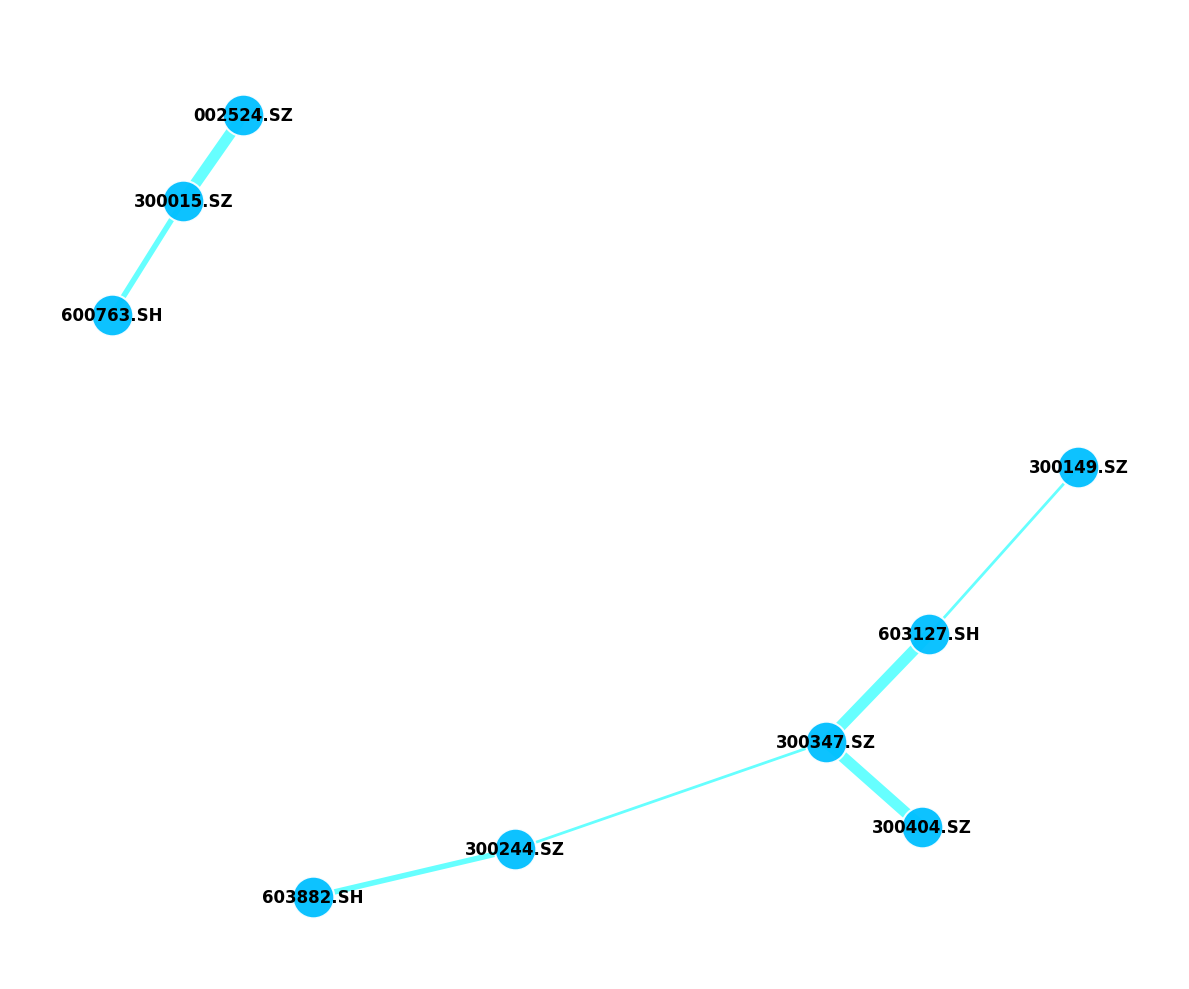

In [2]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

# === Step 1: 输入邻接矩阵（你的数据） ===
relation_matrix = np.array([[0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 4., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 4., 0., 0., 0., 0., 0., 0., 0., 0., 2., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 2.],
       [0., 0., 0., 0., 0., 0., 0., 1., 0., 4., 0., 0., 0., 4., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 4., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 2., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 1., 0., 4., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 2., 0., 0., 0., 0., 0., 0., 0.]])

# === Step 2: 设置节点名称（你可以使用 all_stock.columns[:15]） ===
node_names = ['002044.SZ',
 '002173.SZ',
 '002219.SZ',
 '002524.SZ',
 '300015.SZ',
 '300143.SZ',
 '300149.SZ',
 '300244.SZ',
 '300347.SZ',
 '300404.SZ',
 '600645.SH',
 '600721.SH',
 '600763.SH',
 '603127.SH',
 '603882.SH']
 # 示例名称

# === Step 3: 创建图对象 ===
G = nx.Graph()
N = relation_matrix.shape[0]
for i in range(N):
    for j in range(i + 1, N):
        w = relation_matrix[i, j]
        if w > 0:
            G.add_edge(node_names[i], node_names[j], weight=w)

# === Step 4: 可视化设置 ===
pos = nx.spring_layout(G, seed=42)
plt.figure(figsize=(12, 10))
plt.axis('off')
plt.gca().set_facecolor('#0a0a0a')  # 黑色背景

# 节点美化
nx.draw_networkx_nodes(
    G, pos,
    node_color='deepskyblue',
    node_size=900,
    edgecolors='white',
    linewidths=1.5,
    alpha=0.95
)

# 边美化（按边权重调整宽度）
weights = [G[u][v]['weight'] for u, v in G.edges()]
norm_weights = [w / max(weights) * 8 for w in weights] if weights else []
nx.draw_networkx_edges(
    G, pos,
    width=norm_weights,
    edge_color='aqua',
    alpha=0.6
)

# 标签
nx.draw_networkx_labels(
    G, pos,
    font_color='black',
    font_size=12,
    font_weight='bold'
)

# 标题
plt.title("tech答记者问关系图", color='white', fontsize=16)

# === Step 5: 导出为 SVG ===
plt.savefig("***********QAgraph.svg", format='svg', bbox_inches='tight', dpi=300)
plt.tight_layout()
plt.show()

C:\Users\perfe\AppData\Local\Temp\ipykernel_12840\2115695079.py:86: UserWarning: Glyph 31572 (\N{CJK UNIFIED IDEOGRAPH-7B54}) missing from current font.
  fig.savefig("D:/paper/onging/bankgraph/techQAgraph.svg",
C:\Users\perfe\AppData\Local\Temp\ipykernel_12840\2115695079.py:86: UserWarning: Glyph 35760 (\N{CJK UNIFIED IDEOGRAPH-8BB0}) missing from current font.
  fig.savefig("D:/paper/onging/bankgraph/techQAgraph.svg",
C:\Users\perfe\AppData\Local\Temp\ipykernel_12840\2115695079.py:86: UserWarning: Glyph 32773 (\N{CJK UNIFIED IDEOGRAPH-8005}) missing from current font.
  fig.savefig("D:/paper/onging/bankgraph/techQAgraph.svg",
C:\Users\perfe\AppData\Local\Temp\ipykernel_12840\2115695079.py:86: UserWarning: Glyph 38382 (\N{CJK UNIFIED IDEOGRAPH-95EE}) missing from current font.
  fig.savefig("D:/paper/onging/bankgraph/techQAgraph.svg",
C:\Users\perfe\AppData\Local\Temp\ipykernel_12840\2115695079.py:86: UserWarning: Glyph 20851 (\N{CJK UNIFIED IDEOGRAPH-5173}) missing from current font.

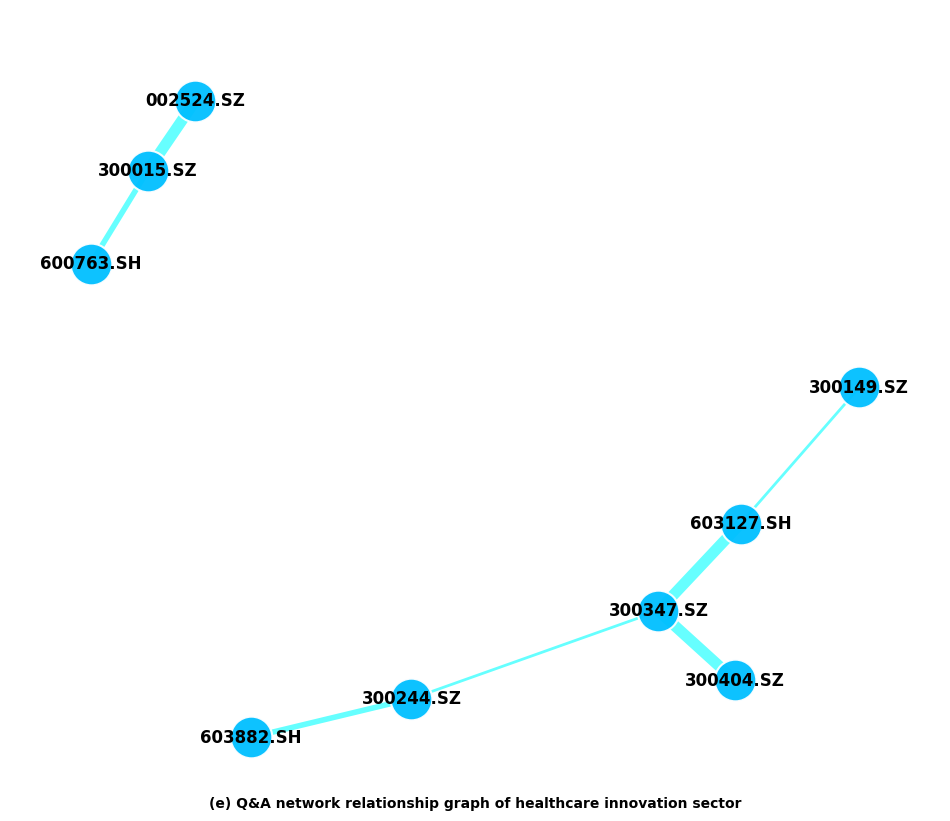

In [9]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

# === Step 1: 输入邻接矩阵（你的数据） ===
relation_matrix = np.array([
    [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
    [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
    [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
    [0., 0., 0., 0., 4., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
    [0., 0., 0., 4., 0., 0., 0., 0., 0., 0., 0., 0., 2., 0., 0.],
    [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
    [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0.],
    [0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 2.],
    [0., 0., 0., 0., 0., 0., 0., 1., 0., 4., 0., 0., 0., 4., 0.],
    [0., 0., 0., 0., 0., 0., 0., 0., 4., 0., 0., 0., 0., 0., 0.],
    [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
    [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
    [0., 0., 0., 0., 2., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
    [0., 0., 0., 0., 0., 0., 1., 0., 4., 0., 0., 0., 0., 0., 0.],
    [0., 0., 0., 0., 0., 0., 0., 2., 0., 0., 0., 0., 0., 0., 0.]
])

# === Step 2: 设置节点名称 ===
node_names = ['002044.SZ','002173.SZ','002219.SZ','002524.SZ','300015.SZ',
              '300143.SZ','300149.SZ','300244.SZ','300347.SZ','300404.SZ',
              '600645.SH','600721.SH','600763.SH','603127.SH','603882.SH']

# === Step 3: 创建图对象 ===
G = nx.Graph()
N = relation_matrix.shape[0]
for i in range(N):
    for j in range(i + 1, N):
        w = relation_matrix[i, j]
        if w > 0:
            G.add_edge(node_names[i], node_names[j], weight=w)

# === Step 4: 可视化设置 ===
pos = nx.spring_layout(G, seed=42)
fig, ax = plt.subplots(figsize=(12, 10))
ax.axis('off')
ax.set_facecolor('#0a0a0a')  # 黑色背景

# 节点
nx.draw_networkx_nodes(
    G, pos,
    node_color='deepskyblue',
    node_size=900,
    edgecolors='white',
    linewidths=1.5,
    alpha=0.95,
    ax=ax
)

# 边
weights = [G[u][v]['weight'] for u, v in G.edges()]
norm_weights = [w / max(weights) * 8 for w in weights] if weights else []
nx.draw_networkx_edges(
    G, pos,
    width=norm_weights,
    edge_color='aqua',
    alpha=0.6,
    ax=ax
)

# 标签
nx.draw_networkx_labels(
    G, pos,
    font_color='black',
    font_size=12,
    font_weight='bold',
    ax=ax
)

# 标题
ax.set_title("tech答记者问关系图", color='white', fontsize=16)

# === 在图下方添加说明文字 ===
ax.text(0.5, -0.005,
        '(e) Q&A network relationship graph of healthcare innovation sector',
        transform=ax.transAxes,
        ha='center',
        fontsize=10, fontweight='bold')

# === Step 5: 保存为 SVG ===
fig.savefig("*******QAgraph.svg",
            format='svg', dpi=300, bbox_inches='tight', pad_inches=0.2)

plt.show()

